In [1]:
import sys
print(sys.executable)

D:\Anaconda_file\envs\retailpulse\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned_transactions.csv")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Shape:", df.shape)
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Shape: (42750, 9)
Date range: 2023-01-01 08:00:00 to 2024-09-05 18:00:00


In [3]:
# Create daily revenue series

daily_revenue = (
    df.groupby(df["InvoiceDate"].dt.date)["Revenue"]
    .sum()
    .reset_index()
)

daily_revenue.columns = ["Date", "Revenue"]
daily_revenue["Date"] = pd.to_datetime(daily_revenue["Date"])

# Sort by date
daily_revenue = daily_revenue.sort_values("Date").reset_index(drop=True)

print("Daily revenue shape:", daily_revenue.shape)
print("\nDate range:")
print(daily_revenue["Date"].min(), "to", daily_revenue["Date"].max())

print("\nFirst 5 rows:")
print(daily_revenue.head())

Daily revenue shape: (603, 2)

Date range:
2023-01-01 00:00:00 to 2024-09-05 00:00:00

First 5 rows:
        Date  Revenue
0 2023-01-01  3273.82
1 2023-01-02  4966.97
2 2023-01-03  4530.42
3 2023-01-04  4158.87
4 2023-01-05  4249.96


In [4]:
# Convert daily revenue into weekly revenue

weekly_revenue = (
    daily_revenue
    .set_index("Date")["Revenue"]
    .resample("W")
    .sum()
    .reset_index()
)

print("Weekly revenue shape:", weekly_revenue.shape)

print("\nDate range:")
print(
    weekly_revenue["Date"].min(),
    "to",
    weekly_revenue["Date"].max()
)

print("\nFirst 5 weeks:")
print(weekly_revenue.head())

Weekly revenue shape: (89, 2)

Date range:
2023-01-01 00:00:00 to 2024-09-08 00:00:00

First 5 weeks:
        Date   Revenue
0 2023-01-01   3273.82
1 2023-01-08  30168.34
2 2023-01-15  30614.09
3 2023-01-22  29535.99
4 2023-01-29  33925.63


In [5]:
# Convert daily revenue into weekly revenue

weekly_revenue = (
    daily_revenue
    .set_index("Date")["Revenue"]
    .resample("W")
    .sum()
    .reset_index()
)

print("Weekly revenue shape:", weekly_revenue.shape)

print("\nDate range:")
print(
    weekly_revenue["Date"].min(),
    "to",
    weekly_revenue["Date"].max()
)

print("\nFirst 5 weeks:")
print(weekly_revenue.head())

Weekly revenue shape: (89, 2)

Date range:
2023-01-01 00:00:00 to 2024-09-08 00:00:00

First 5 weeks:
        Date   Revenue
0 2023-01-01   3273.82
1 2023-01-08  30168.34
2 2023-01-15  30614.09
3 2023-01-22  29535.99
4 2023-01-29  33925.63


In [6]:
# Plot weekly revenue trend

plt.figure(figsize=(12, 5))
plt.plot(
    weekly_revenue["Date"],
    weekly_revenue["Revenue"]
)

plt.title("Weekly Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 1 Axes>

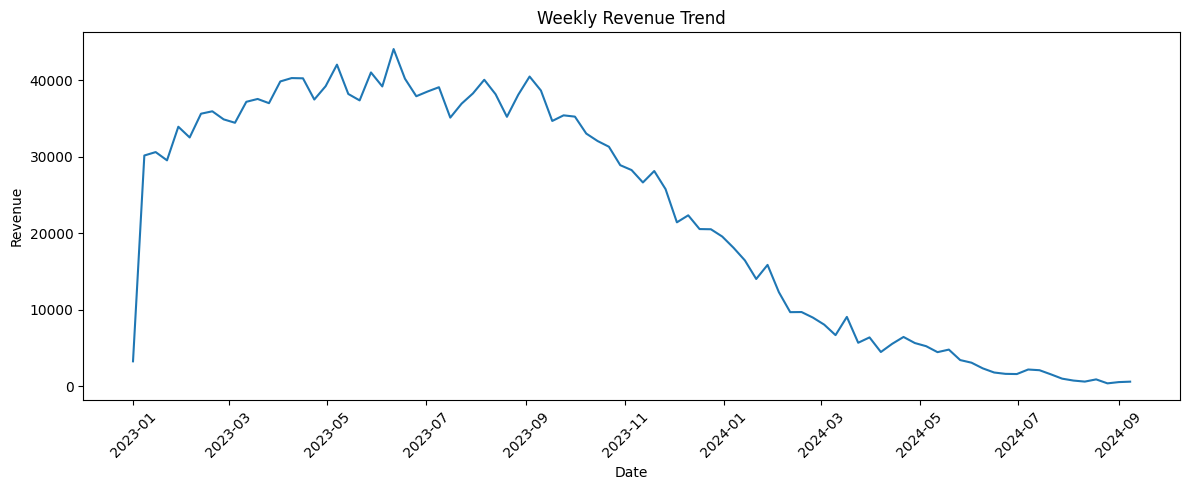

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    weekly_revenue["Date"],
    weekly_revenue["Revenue"]
)

ax.set_title("Weekly Revenue Trend")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [8]:
# Split weekly revenue into training and testing data

test_weeks = 12

train = weekly_revenue.iloc[:-test_weeks].copy()
test = weekly_revenue.iloc[-test_weeks:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nTesting period:")
print(test["Date"].min(), "to", test["Date"].max())

Training observations: 77
Testing observations: 12

Training period:
2023-01-01 00:00:00 to 2024-06-16 00:00:00

Testing period:
2024-06-23 00:00:00 to 2024-09-08 00:00:00


In [9]:


from statsmodels.tsa.statespace.sarimax import SARIMAX

# Prepare time series
train_series = train.set_index("Date")["Revenue"]

# SARIMA model
sarima_model = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

print("SARIMA model training completed.")
print(sarima_result.summary())

D:\Anaconda_file\envs\retailpulse\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
D:\Anaconda_file\envs\retailpulse\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


SARIMA model training completed.
                                     SARIMAX Results                                     
Dep. Variable:                           Revenue   No. Observations:                   77
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 4)   Log Likelihood                -595.175
Date:                           Thu, 08 Oct 2026   AIC                           1200.349
Time:                                   20:48:58   BIC                           1211.297
Sample:                               01-01-2023   HQIC                          1204.675
                                    - 06-16-2024                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1013      0.292     -0.347      0.728      -0.673       0.471
ma.L1     

In [10]:
# Forecast the next 12 weeks

forecast = sarima_result.get_forecast(steps=len(test))

forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# Create forecast dataframe
forecast_df = pd.DataFrame({
    "Date": test["Date"].values,
    "Actual_Revenue": test["Revenue"].values,
    "Forecast_Revenue": forecast_mean.values
})

print(forecast_df)

         Date  Actual_Revenue  Forecast_Revenue
0  2024-06-23         1636.54       1166.966481
1  2024-06-30         1611.48        487.625040
2  2024-07-07         2204.11         96.578947
3  2024-07-14         2112.83       -116.552504
4  2024-07-21         1575.71       -971.515375
5  2024-07-28         1008.85      -1595.564539
6  2024-08-04          759.44      -2033.656186
7  2024-08-11          624.43      -2289.046755
8  2024-08-18          913.83      -3116.757731
9  2024-08-25          394.70      -3748.000670
10 2024-09-01          560.23      -4179.970552
11 2024-09-08          615.99      -4429.862062


In [11]:
# Train SARIMA using log-transformed revenue
# Log transformation helps stabilize variance and keeps forecasts positive.

train_log = np.log1p(train.set_index("Date")["Revenue"])

sarima_log_model = SARIMAX(
    train_log,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 4),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_log_result = sarima_log_model.fit(disp=False)

print("Log-SARIMA model training completed.")
print("AIC:", round(sarima_log_result.aic, 2))

Log-SARIMA model training completed.
AIC: -77.39


D:\Anaconda_file\envs\retailpulse\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
D:\Anaconda_file\envs\retailpulse\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


In [12]:
# Forecast the next 12 weeks using the log-SARIMA model

log_forecast = sarima_log_result.get_forecast(steps=len(test))

# Convert predictions back to original revenue scale
forecast_mean = np.expm1(log_forecast.predicted_mean)

forecast_df = pd.DataFrame({
    "Date": test["Date"].values,
    "Actual_Revenue": test["Revenue"].values,
    "Forecast_Revenue": forecast_mean.values
})

print(forecast_df)

         Date  Actual_Revenue  Forecast_Revenue
0  2024-06-23         1636.54       1675.290876
1  2024-06-30         1611.48       1398.499840
2  2024-07-07         2204.11       1343.439114
3  2024-07-14         2112.83       1204.635079
4  2024-07-21         1575.71       1069.186790
5  2024-07-28         1008.85        913.304946
6  2024-08-04          759.44        864.474734
7  2024-08-11          624.43        780.207471
8  2024-08-18          913.83        689.582054
9  2024-08-25          394.70        590.413940
10 2024-09-01          560.23        558.051484
11 2024-09-08          615.99        504.033977


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = forecast_df["Actual_Revenue"]
predicted = forecast_df["Forecast_Revenue"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(
    np.abs((actual - predicted) / actual)
) * 100

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

MAE:  284.80
RMSE: 409.73
MAPE: 22.56%


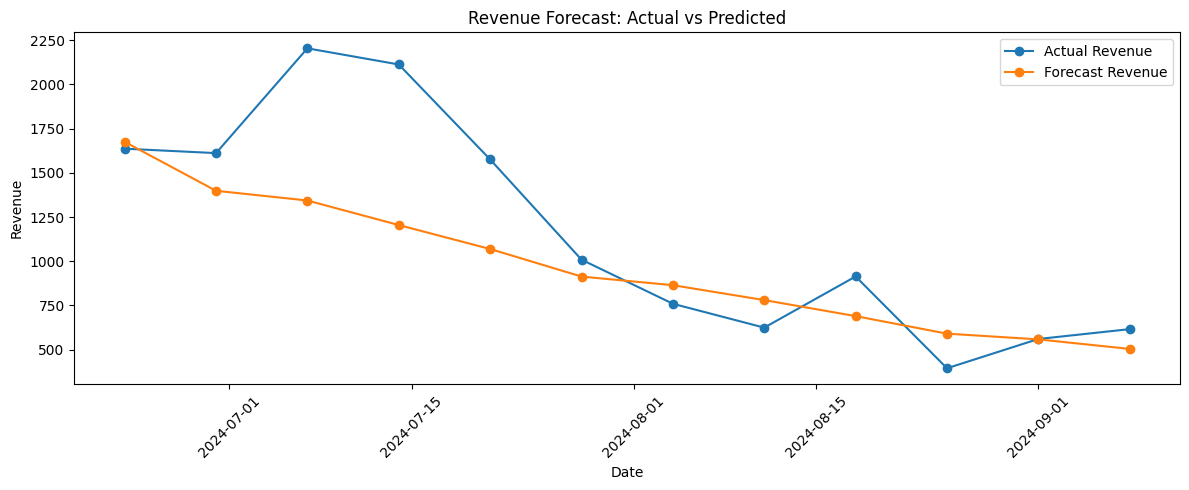

In [14]:
# Plot actual vs forecast revenue

plt.figure(figsize=(12, 5))

plt.plot(
    forecast_df["Date"],
    forecast_df["Actual_Revenue"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Forecast_Revenue"],
    marker="o",
    label="Forecast Revenue"
)

plt.title("Revenue Forecast: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
import os
import joblib

# Make sure the models directory exists
os.makedirs("../models", exist_ok=True)

# Save the log-SARIMA model
forecast_model_path = "../models/forecast_model.pkl"

joblib.dump(
    sarima_log_result,
    forecast_model_path
)

print("Forecast model saved successfully:")
print(forecast_model_path)

Forecast model saved successfully:
../models/forecast_model.pkl


In [16]:
# Save forecast results

forecast_df.to_csv(
    "../data/revenue_forecast.csv",
    index=False
)

# Save forecast metrics
forecast_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [mae, rmse, mape]
})

forecast_metrics.to_csv(
    "../data/forecast_metrics.csv",
    index=False
)

print("Forecast results saved successfully.")
print("Files created:")
print("../data/revenue_forecast.csv")
print("../data/forecast_metrics.csv")

Forecast results saved successfully.
Files created:
../data/revenue_forecast.csv
../data/forecast_metrics.csv
